<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula25c%20-%20linear%20regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

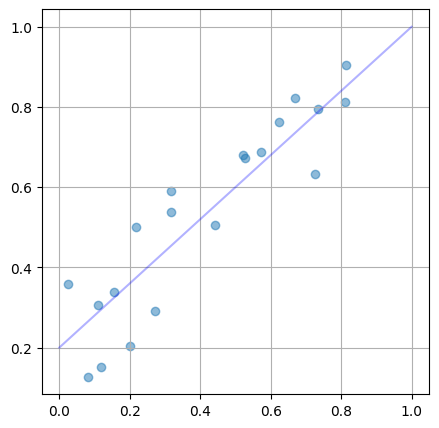

In [186]:
import numpy as np
from matplotlib import pyplot as plt

def create_regression_dataset(n=20, coefs=[1], intercept=-1):
  X = np.random.rand(n, 1)
  noise = np.random.randn(n, 1) * 0.1
  y = X * coefs + intercept + noise
  return X, y

def plot_dataset(X, y):
  plt.scatter(X[:,0], y, alpha=0.5)
  plt.grid(True)

def plot_line(coefs, intercept, color="green"):
  xs = np.array([0,1])
  ys = coefs * xs + intercept
  plt.plot(xs, ys, c=color, alpha=0.3)

coefs = [0.8]
intercept = 0.2
X, y = create_regression_dataset(20, coefs, intercept)

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plt.show()

rmse: 0.13411137940363677
coefs: [0.47275278]		intercept: 0.3475747387119887


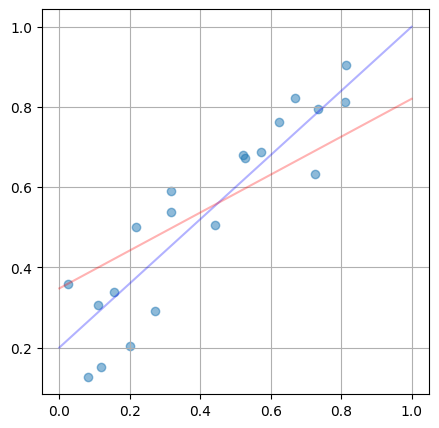

In [187]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import root_mean_squared_error

class LinearRegression(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=100, learning_rate=0.1):
    self.max_iter = max_iter
    self.learning_rate = learning_rate

  def fit(self, X, y):
    y = y.reshape(-1)
    self.coefs = np.zeros(X.shape[1])
    self.intercept = 0
    for _ in range(self.max_iter):
      cost = 0
      y_pred = self.predict(X)
      error = y - y_pred
      self.coefs += X.T @ error * self.learning_rate / X.shape[0]
      self.intercept += error.sum() * self.learning_rate / X.shape[0]
    return self

  def predict(self, X):
    logits = X @ self.coefs + self.intercept
    y_pred = logits
    return y_pred


model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print(f"rmse: {root_mean_squared_error(y, y_pred)}")
print(f"coefs: {model.coefs}\t\tintercept: {model.intercept}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plot_line(model.coefs, model.intercept, color="red")
plt.show()

rmse: 0.15410947840190609


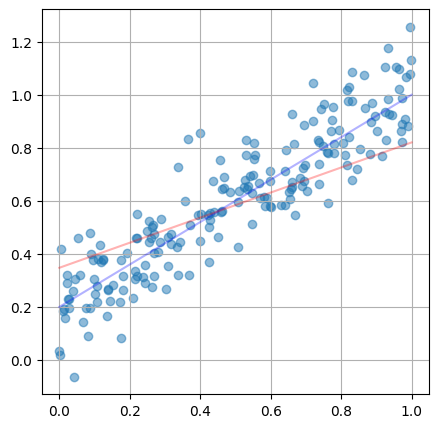

In [188]:
X_test, y_test = create_regression_dataset(200, coefs, intercept)
y_pred = model.predict(X_test)
print(f"rmse: {root_mean_squared_error(y_test, y_pred)}")

plt.figure(figsize=(5, 5))
plot_dataset(X_test, y_test)
plot_line(coefs, intercept, color="blue")
plot_line(model.coefs, model.intercept, color="red")
plt.show()